# Annual Sales Forecast | Analysis and Documentation

Plots and tables documenting the data, model accuracy, error patterns, clustering, and current forecasts.

- Data is read live from the same sources as the model notebook (`sales_forecast/sources.py`).
- Backtest results come from the artifacts saved with the latest model run (`sales-forecast-walkforward.ipynb`),
  so this notebook documents exactly that run. Run the model notebook first.
- Figures are also saved as PNG files to `sales_forecast_results/figures/`.
- Residual sign convention: `log(actual) - log(forecast)`. **Positive (blue) = under-forecast**, **negative (red) = over-forecast**.

## Environment Setup
On Databricks, add the standard `adh_init` cells first.

In [1]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd()
PACKAGE_DIR = Path(os.environ.get("SALES_PACKAGE_DIR", ROOT / ".annual_packages"))
sys.path.insert(0, str(PACKAGE_DIR))
sys.path.insert(0, str(ROOT))

import warnings

import numpy as np
import pandas as pd

from sales_forecast import constants as C
from sales_forecast import plots as P
from sales_forecast import residuals as R
from sales_forecast.metrics import summarize
from sales_forecast.model import SalesForecaster
from sales_forecast.sources import load_inputs
from sales_forecast.transform import (
    build_store_attributes,
    engineer_features,
    prepare_location_attributes,
    prepare_sales_features,
    split_cohorts,
)

warnings.filterwarnings("ignore")
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 40)
try:
    display
except NameError:
    display = print
P.style()

## 1. Load latest data and model

In [2]:
schema = adh.conf.default_schema_qualified if "adh" in globals() else C.FEATURE_SCHEMA
sales_features_raw, location_attributes_raw = load_inputs(spark=globals().get("spark"), schema=schema)
location_attributes = prepare_location_attributes(location_attributes_raw)
df_all = engineer_features(prepare_sales_features(sales_features_raw), build_store_attributes(location_attributes))
labeled, inference = split_cohorts(df_all)

forecaster = SalesForecaster.load(C.MODEL_PATH)
artifacts = forecaster.artifacts_
assert artifacts, "model has no artifacts; rerun sales-forecast-walkforward.ipynb"
print(f"{labeled.shape=} {inference.shape=} model as-of={forecaster.as_of_date_.date()} data as-of={C.AS_OF_DATE.date()}")
if forecaster.as_of_date_ != C.AS_OF_DATE:
    print("NOTE: model was trained at a different as-of date; rerun the model notebook to refresh.")
backtest, backtest_frame = artifacts["backtest"], artifacts["backtest_frame"]
residual_frame, remaining = artifacts["residual_frame"], artifacts["remaining"]

source='files' sales_features.shape=(3432, 76) location_attributes.shape=(8103, 16)
labeled.shape=(1238, 116) inference.shape=(721, 116) model as-of=2026-10-01 data as-of=2026-10-01


## 2. Data overview
Training stores: FSU and DTO stores with a full first year of sales. Cohort = first-anniversary year.

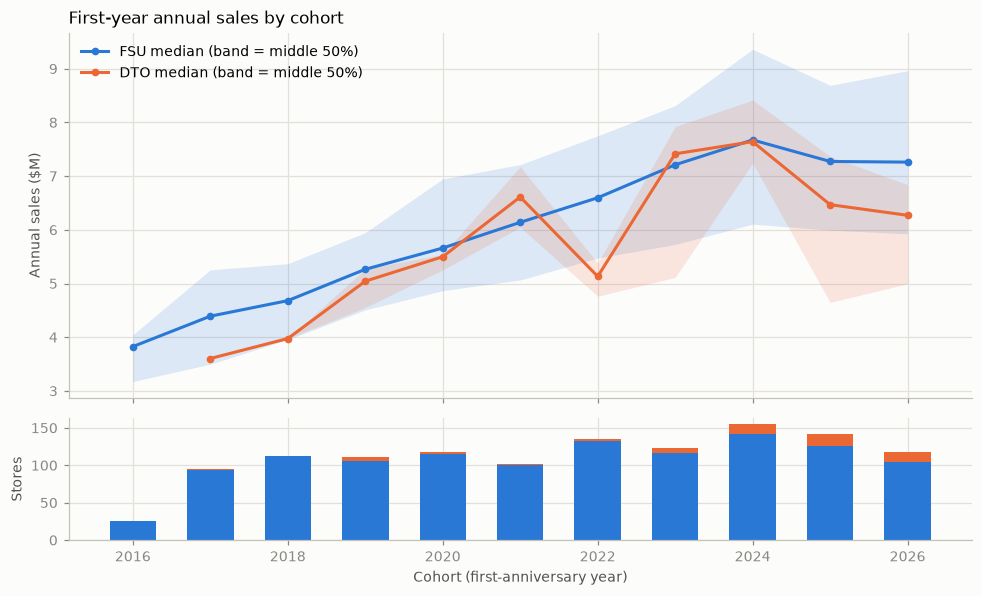

In [3]:
P.cohort_distribution(labeled);

In [4]:
overview = labeled.groupby("cohort").agg(
    stores=("location_num", "size"),
    dto_share=("is_dto", "mean"),
    relocated_share=("is_relocated", "mean"),
    ssam_share=("ssam_flag", "mean"),
    median_sales_m=(C.target, "median"),
    mean_sales_m=(C.target, "mean"),
    p10_sales_m=(C.target, lambda s: s.quantile(0.1)),
    p90_sales_m=(C.target, lambda s: s.quantile(0.9)),
)
overview["median_growth_pct"] = overview["median_sales_m"].pct_change() * 100
display(overview.round(3))

,stores,dto_share,relocated_share,ssam_share,median_sales_m,mean_sales_m,p10_sales_m,p90_sales_m,median_growth_pct
cohort,,,,,,,,,
2016,26,0.000,0.000,0.077,3.826,3.813,2.809,4.924,NaN
2017,95,0.011,0.011,0.021,4.371,4.471,2.920,6.202,14.254
2018,113,0.009,0.044,0.097,4.663,4.761,3.318,6.077,6.687
2019,111,0.045,0.063,0.072,5.260,5.417,3.653,7.202,12.785
2020,118,0.025,0.034,0.119,5.616,5.878,4.422,7.603,6.780
2021,102,0.020,0.078,0.118,6.140,6.399,4.450,8.569,9.323
2022,135,0.022,0.067,0.081,6.572,6.824,4.792,9.307,7.041
2023,123,0.057,0.122,0.138,7.226,7.194,4.995,9.297,9.954
2024,155,0.084,0.110,0.168,7.668,7.864,5.335,10.709,6.106


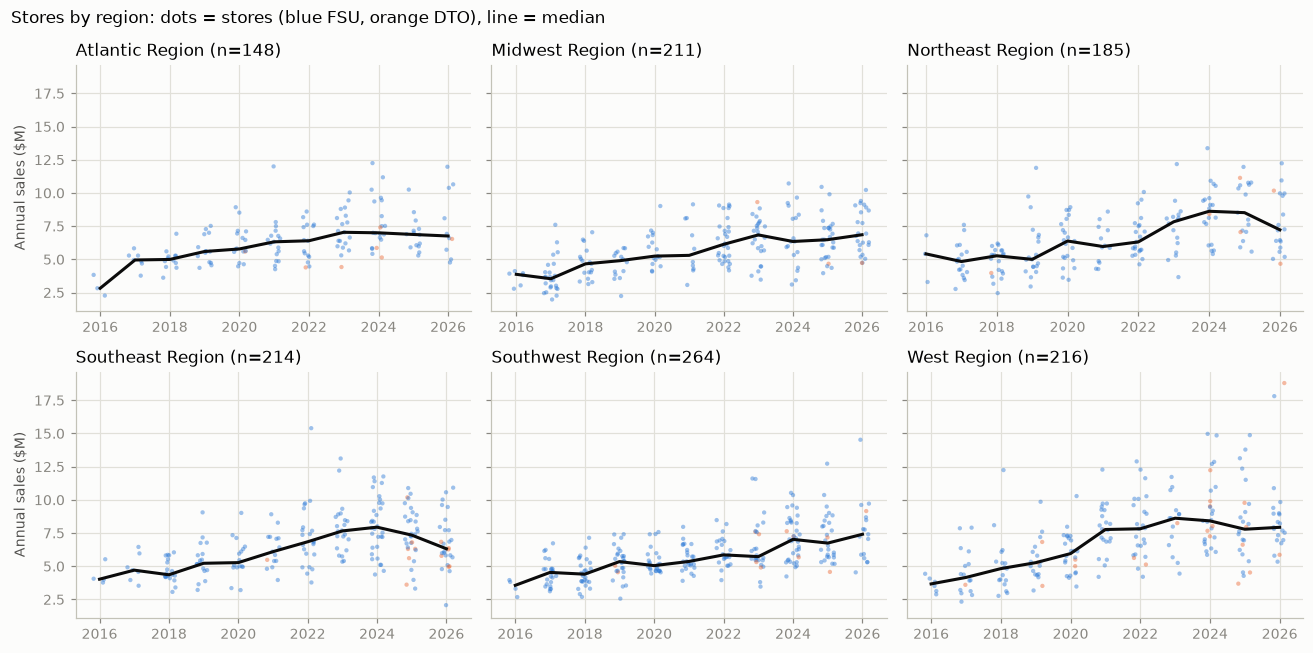

In [5]:
P.region_small_multiples(labeled);

In [6]:
region_table = labeled.pivot_table(index="region", columns="cohort", values=C.target, aggfunc="median")
display(region_table.round(2))

cohort,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
region,,,,,,,,,,,
Atlantic Region,2.83,4.95,5.00,5.59,5.79,6.32,6.40,7.04,7.00,6.88,6.76
Midwest Region,3.87,3.54,4.66,4.90,5.25,5.30,6.14,6.84,6.35,6.48,6.86
Northeast Region,5.41,4.84,5.27,5.00,6.38,5.97,6.32,7.83,8.62,8.52,7.23
Southeast Region,4.03,4.71,4.36,5.23,5.28,6.10,6.84,7.66,7.95,7.35,6.32
Southwest Region,3.57,4.54,4.41,5.35,5.05,5.36,5.86,5.73,7.03,6.75,7.41
West Region,3.67,4.16,4.82,5.27,5.96,7.77,7.82,8.62,8.42,7.79,7.93


**Observations:** cohort medians grew about 6-13% a year until 2024, then fell in 2025-2026. DTO cohorts are small
(13-16 stores a year) and volatile. Relocated stores (about 8-12% of recent cohorts) sell well above average.

## 3. What drives sales
Rank correlation of each feature with log sales, and the base models' feature importance.

In [7]:
numeric_features = [c for c in forecaster.base_.selector_.features_ if c not in ("region_code", "state_code")]
correlation = labeled[numeric_features].corrwith(labeled[C.log_target], method="spearman").sort_values()
correlation_table = pd.concat([correlation.head(8), correlation.tail(12)]).rename("spearman_vs_log_sales")
display(correlation_table.round(3).to_frame())

,spearman_vs_log_sales
ssam_flag,-0.125
close_highway_min,-0.121
close_highway_dist,-0.121
boundary_10,-0.087
cannibalization_score,-0.073
boundary_5,-0.069
worker_resident_ratio,-0.051
daytime_resident_ratio,-0.048
log_median_average_daily_traffic_3,0.137
neighbor_spread,0.149


,lgb_log,lgb_huber,mean
log_avg_monthly_sales_75th_1year,16.73,3.20,9.97
years_since_2015,9.20,3.77,6.49
log_avg_monthly_sales_mean_1year,10.65,1.67,6.16
te_submarket,3.65,6.38,5.02
trend,7.34,1.58,4.46
cannibalization_score,3.22,5.54,4.38
log_max_average_daily_traffic_1,2.78,5.37,4.08
is_relocated,3.23,4.32,3.78
log_avg_monthly_sales_closest_1year,2.94,2.82,2.88
boundary_5,2.24,3.50,2.87


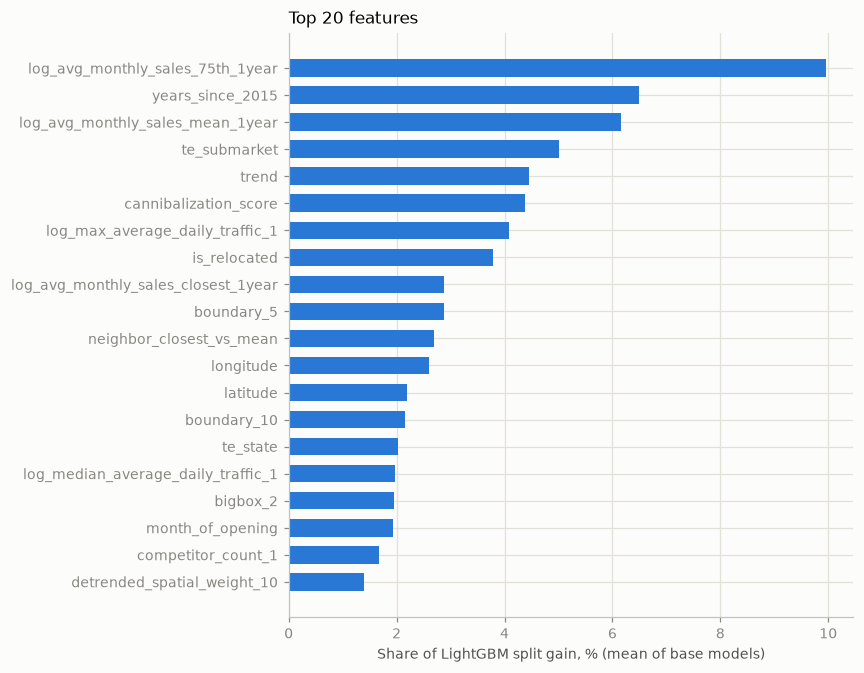

In [8]:
importance = forecaster.feature_importance()
P.feature_importance_bars(importance);
display(importance.head(20).round(2))

**Observations:** nearby-store sales, the time trend, and the time-safe spatial and target-encoded features carry most of
the signal. Demographics and traffic have weak individual correlations (|rho| < 0.2).

## 4. Backtest accuracy
Walk-forward: each cohort is predicted by a model and corrector that only saw earlier cohorts.

In [ ]:
P.accuracy_by_cohort(backtest);
accuracy_table = backtest.pivot(index="model", columns="cohort", values=["WAPE", "MAPE"]) * 100
for metric in ["WAPE", "MAPE"]:
    accuracy_table[(metric, "avg")] = accuracy_table[metric].mean(axis=1)
display(accuracy_table.sort_index(axis=1).round(1))

In [ ]:
scored = backtest_frame[backtest_frame["cohort"].isin(C.BACKTEST_COHORTS)].copy()
P.actual_vs_forecast(scored);

In [ ]:
segment_rows = []
scored["cannibalization_band"] = pd.cut(scored["cannibalization_score"], [-1, 0, 5, 15, 30, 1000], labels=["0", "1-5", "6-15", "16-30", "31+"])
for column in ["subtype", "region", "is_relocated", "ssam_flag", "cannibalization_band"]:
    for value, part in scored.groupby(column, observed=True):
        segment_rows.append(dict(segment=column, value=value, **summarize(part[C.target], np.exp(part["log_corrected"]))))
segment_metrics = pd.DataFrame(segment_rows)
display(segment_metrics.round(3))

In [ ]:
scored["forecast_m"] = np.exp(scored["log_corrected"])
scored["error_pct"] = (scored["forecast_m"] - scored[C.target]) / scored[C.target] * 100
largest_misses = scored.reindex(scored["error_pct"].abs().sort_values(ascending=False).index).head(15)
display(largest_misses[["location_num", "location_name", "cohort", "state", "subtype", "is_relocated", C.target, "forecast_m", "error_pct"]].round(2))

## 5. Residual patterns: which errors repeat?
Out-of-fold residuals of the **base** model, cohort median removed. A pattern is worth correcting only if an earlier
cohort's error predicts the next cohort's error.

In [ ]:
P.lag_correlation_bars(artifacts["group_lags"]);
display(artifacts["group_lags"].round(2))

In [ ]:
segments = residual_frame.assign(
    opening_quarter="Q" + ((residual_frame["month_of_opening"] - 1) // 3 + 1).astype(str),
    cannibalization_band=pd.cut(residual_frame["cannibalization_score"], [-1, 5, 15, 30, 1000], labels=["0-5", "6-15", "16-30", "31+"]),
)
rows = []
for column, label in [("is_relocated", "relocated"), ("ssam_flag", "SSAM"), ("is_dto", "DTO"), ("opening_quarter", "opened"), ("cannibalization_band", "cannibalization")]:
    table = segments.groupby([column, "cohort"], observed=True)["centred"].mean().unstack() * 100
    table.index = [f"{label}={v}" for v in table.index]
    rows.append(table)
segment_bias = pd.concat(rows)
P.bias_heatmap(segment_bias, "Base-model error by segment and cohort (repeating patterns)", "segment_bias");

In [ ]:
region_bias = residual_frame.groupby(["region", "cohort"])["centred"].mean().unstack() * 100
P.bias_heatmap(region_bias, "Base-model error by region and cohort (no repeating pattern)", "region_bias");

In [ ]:
display(artifacts["spatial_lags"].round(2))
display(artifacts["bin_persistence"].round(3))

**Observations:** relocated (under-forecast), DTO, SSAM, Q4 openings, and high cannibalization (over-forecast) keep the same
sign year after year, so the residual corrector learns offsets for them. Region, state, DMA, and the overall cohort level
do not repeat. Nearby-store sales already absorb local price and demand levels.

In [ ]:
offsets = (forecaster.corrector_.factor_offsets() * 100).rename("offset_pct_log").to_frame()
offsets["meaning"] = [
    "relocated store vs new site",
    "SSAM store",
    "DTO vs FSU",
    "opened Apr-Jun vs Jan-Mar",
    "opened Jul-Sep vs Jan-Mar",
    "opened Oct-Dec vs Jan-Mar",
    "per +1 in log(1 + cannibalization score)",
]
display(offsets.round(1))
print(f"level anchor: strength={C.LEVEL_ANCHOR_STRENGTH}, latest cohort={forecaster.corrector_.latest_cohort_}, "
      f"median=${np.exp(forecaster.corrector_.latest_median_):.2f}M, growth={C.LEVEL_ANNUAL_GROWTH}")

## 6. Clustering of remaining errors
Residuals **after** the correction (backtest cohorts). K-means on standardized location characteristics.

In [ ]:
cluster_summary = remaining.groupby("cluster").agg(
    stores=("centred", "size"),
    mean_residual_pct=("centred", lambda s: s.mean() * 100),
    under_forecast_share=("centred", lambda s: (s > 0.15).mean()),
    over_forecast_share=("centred", lambda s: (s < -0.15).mean()),
    median_sales_m=(C.target, "median"),
)
P.cluster_profile(artifacts["cluster_centroids"], cluster_summary);
display(cluster_summary.round(3))

In [ ]:
cluster_by_cohort = remaining.groupby(["cluster", "cohort"])["centred"].mean().unstack() * 100
cluster_by_cohort.index = [f"C{c}" for c in cluster_by_cohort.index]
P.bias_heatmap(cluster_by_cohort, "Remaining error by cluster and cohort (clusters do not persist)", "cluster_bias");

In [ ]:
P.under_over_bars(artifacts["under_over"]);
display(artifacts["under_over"].round(2))

**Observations:** cluster errors are small and change sign from cohort to cohort, so location-type clusters are not used
as a correction. After the correction, under- and over-forecast stores differ only slightly (below 0.2 SD on every feature):
under-forecast stores sit somewhat closer to highways and in denser, higher-income, higher food-spend areas; over-forecast
stores have a closest neighbour that sells well above the local average and slightly higher traffic counts. The remaining
error is mostly store-specific.

## 7. Current forecasts
Pipeline stores and existing stores without a full first year, from the saved model.

In [ ]:
forecast = forecaster.predict(inference)
P.forecast_distribution(forecast, labeled);
forecast_summary = forecast.groupby(["location_type", "cohort"]).agg(
    stores=("location_num", "size"),
    median_forecast_m=("forecast_annual_sales", lambda s: s.median() / 1e6),
    p10_m=("forecast_annual_sales", lambda s: s.quantile(0.1) / 1e6),
    p90_m=("forecast_annual_sales", lambda s: s.quantile(0.9) / 1e6),
    relocated=("is_relocated", "sum"),
    placeholder_dates=("open_date_placeholder", "sum"),
)
display(forecast_summary.round(2))

**Reading the forecast spread:** forecasts are narrower than actual sales because a forecast is an expected value.
Store-level uncertainty is roughly the backtest error (WAPE about 18%), so individual stores will spread out about as
widely as the latest cohort's actuals.

In [ ]:
by_region = forecast[forecast["location_type"] == "pipeline"].groupby("region").agg(
    stores=("location_num", "size"),
    median_forecast_m=("forecast_annual_sales", lambda s: s.median() / 1e6),
    total_forecast_m=("forecast_annual_sales", lambda s: s.sum() / 1e6),
)
display(by_region.round(2))
print(f"figures saved to {C.FIGURE_DIR}")